# Option pricing engine, SPY implied-volatility surface and delta-hedging study
*Sam Berman, University College Dublin*

This notebook runs the whole project end to end from the cached data in `data/raw/`
(downloaded on first run by `src/data.py`). Every number quoted in the README is produced here.
All logic lives in `src/`; the notebook only calls it and displays the results.

1. Pricing library: Black–Scholes–Merton, CRR binomial trees, Monte Carlo
2. Implied volatility: cleaning the SPY chain, the smile, the surface
3. Delta hedging a short 1-month ATM SPY call, 2005–2026

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import bsm, binomial, montecarlo, data, pricing_report, surface, hedging
from src.implied_vol import implied_vol
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 160)
FIG, RES = ROOT / "figures", ROOT / "results"
data.download_all()  # no-op if everything is cached

## 1. Pricing library
### 1.1 Black–Scholes–Merton against Hull's textbook examples

In [2]:
rows = [
    ("Hull Ex. 15.6 call  (S=42,K=40,r=10%,σ=20%,T=0.5)", bsm.price(42, 40, 0.5, 0.10, 0, 0.2, "call"), 4.76),
    ("Hull Ex. 15.6 put", bsm.price(42, 40, 0.5, 0.10, 0, 0.2, "put"), 0.81),
    ("Hull index call (S=930,K=900,r=8%,q=3%,σ=20%,T=2/12)", bsm.price(930, 900, 2/12, 0.08, 0.03, 0.2, "call"), 51.83),
]
g = bsm.greeks(49, 50, 0.3846, 0.05, 0, 0.2, "call")
for k, ref in [("price", 2.40), ("delta", 0.522), ("gamma", 0.066), ("vega", 12.1), ("theta", -4.31), ("rho", 8.91)]:
    rows.append((f"Hull Greeks example (S=49,K=50): {k}", g[k], ref))
rows.append(("Hull implied vol (c=1.875,S=21,K=20,r=10%,T=0.25)", implied_vol(1.875, 21, 20, 0.25, 0.10, 0.0), 0.235))
pd.DataFrame(rows, columns=["case", "this library", "Hull"])

,case,this library,Hull
0,"Hull Ex. 15.6 call (S=42,K=40,r=10%,σ=20%,T=0.5)",4.7594,4.7600
1,Hull Ex. 15.6 put,0.8086,0.8100
2,"Hull index call (S=930,K=900,r=8%,q=3%,σ=20%,T...",51.8330,51.8300
3,"Hull Greeks example (S=49,K=50): price",2.4005,2.4000
4,"Hull Greeks example (S=49,K=50): delta",0.5216,0.5220
5,"Hull Greeks example (S=49,K=50): gamma",0.0655,0.0660
6,"Hull Greeks example (S=49,K=50): vega",12.1052,12.1000
7,"Hull Greeks example (S=49,K=50): theta",-4.3054,-4.3100
8,"Hull Greeks example (S=49,K=50): rho",8.9066,8.9100
9,"Hull implied vol (c=1.875,S=21,K=20,r=10%,T=0.25)",0.2345,0.2350


Put–call parity holds to machine precision for the BSM formulas (it is tested on a grid in `tests/test_bsm.py`):

In [3]:
S, K, T, r, q, s = 100, 95, 0.75, 0.04, 0.015, 0.25
c, p = bsm.price(S, K, T, r, q, s, "call"), bsm.price(S, K, T, r, q, s, "put")
print(f"C={c:.6f}  P={p:.6f}  parity gap={float(bsm.parity_gap(c, p, S, K, T, r, q)):.2e}")

C=12.005638  P=5.316660  parity gap=7.11e-15


### 1.2 Binomial trees and Monte Carlo

In [4]:
pricing = pricing_report.run()
print(json.dumps(pricing, indent=2, default=str))

{
  "hull_21_1_american_put_5_steps": 4.488459,
  "hull_21_1_american_put_500_steps": 4.283021,
  "bsm_call": 9.319738,
  "bsm_put": 6.393699,
  "crr_call_error_n1000": -0.001963,
  "crr_put_error_n1000": -0.001963,
  "crr_american_put_n1000": 6.700562,
  "max_abs_call_premium_q0": 0.0,
  "atm_put_premium_r4pct": 0.401268,
  "mc_n_paths": 100000,
  "mc_se": {
    "plain": 0.04407,
    "antithetic": 0.03292,
    "control": 0.01815,
    "antithetic+control": 0.00916
  },
  "mc_vrf": {
    "plain": 1.0,
    "antithetic": 1.79,
    "control": 5.9,
    "antithetic+control": 23.16
  },
  "mc_abs_error_in_se": {
    "plain": 0.72,
    "antithetic": 0.93,
    "control": 0.64,
    "antithetic+control": 0.97
  }
}


,n_steps,euro_put_crr,bsm_put,euro_put_error,amer_put_crr
0,10,6.2001,6.3937,-0.1936,6.6013
1,50,6.3545,6.3937,-0.0392,6.6821
2,100,6.3741,6.3937,-0.0196,6.6918
3,500,6.3898,6.3937,-0.0039,6.6996
4,1000,6.3917,6.3937,-0.0020,6.7006
5,2000,6.3927,6.3937,-0.0010,6.7010


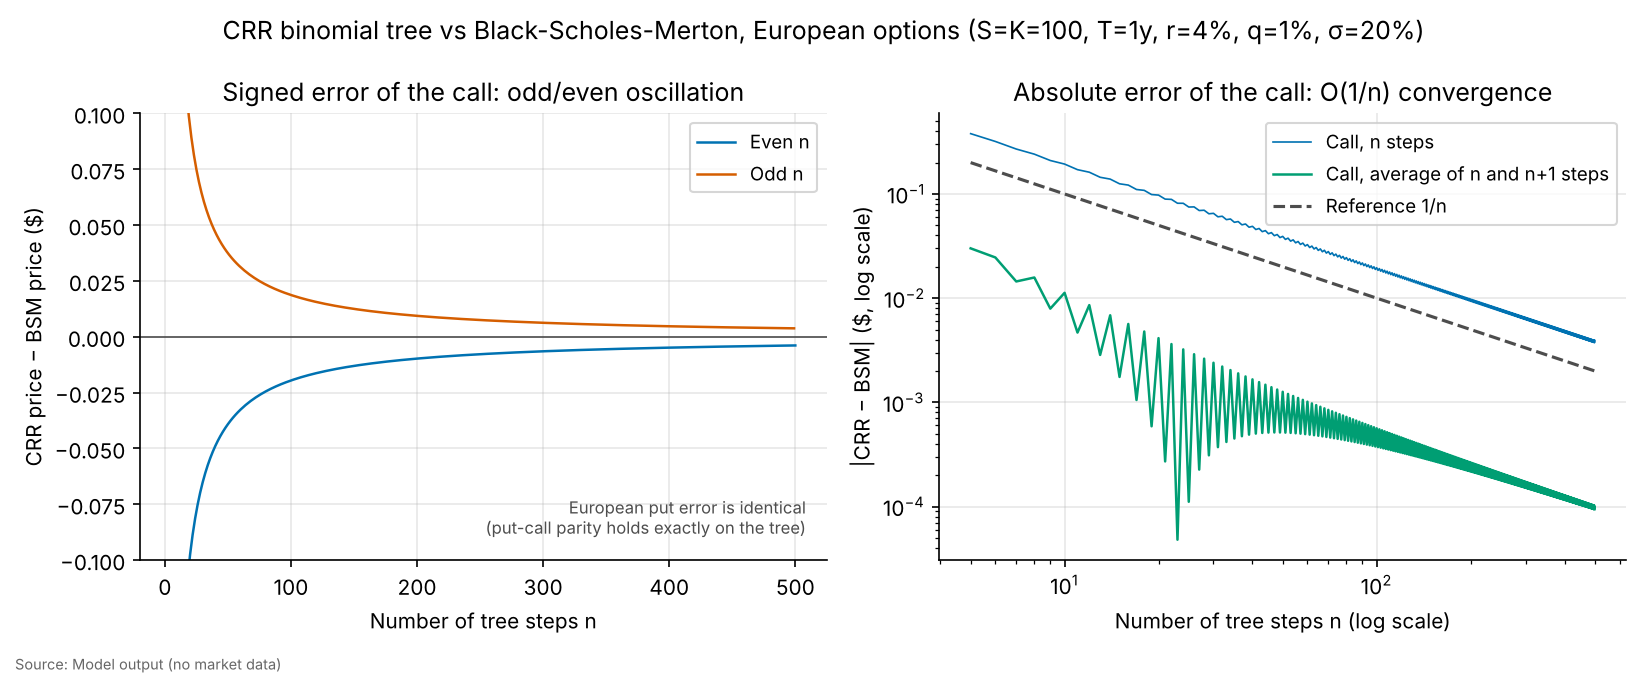

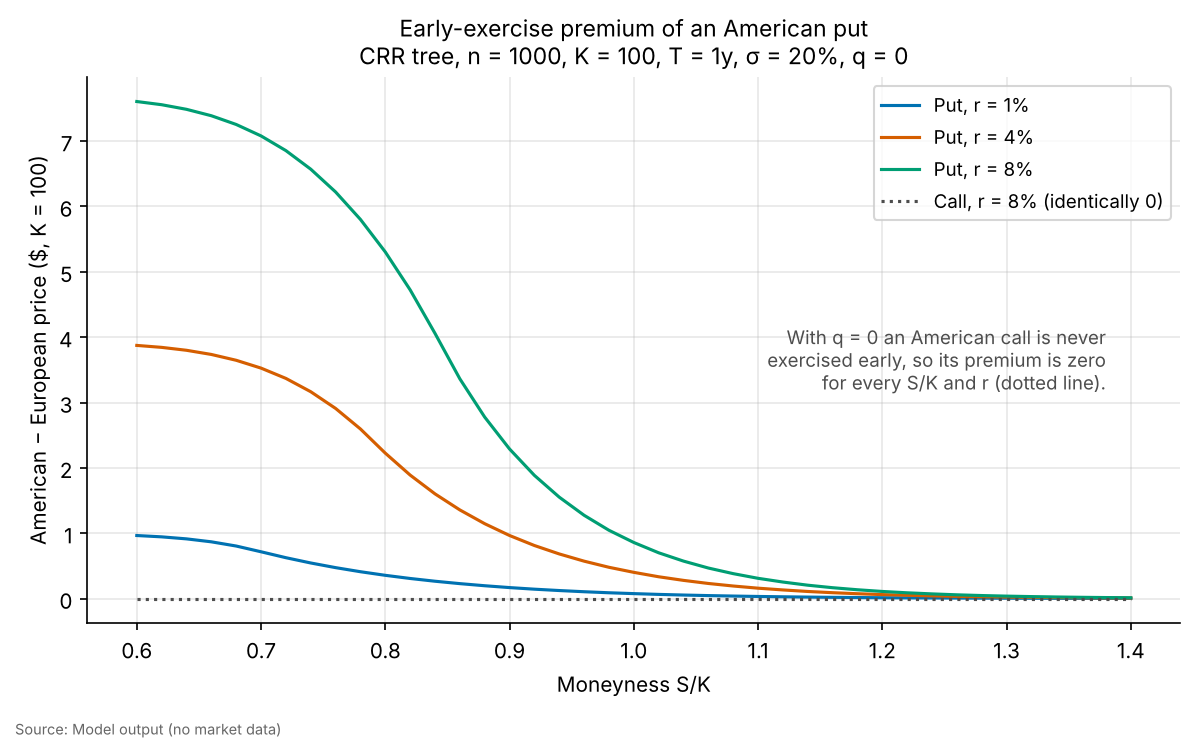

In [5]:
display(pd.read_csv(RES / "crr_convergence.csv"))
display(Image(FIG / "01_crr_convergence.png"))
display(Image(FIG / "02_american_put_premium.png"))

,method,price,std_error,bsm_price,abs_error_in_se,variance_reduction_factor
0,plain,9.2882,0.0441,9.3197,0.7157,1.0000
1,antithetic,9.2891,0.0329,9.3197,0.9304,1.7921
2,control,9.3080,0.0181,9.3197,0.6448,5.8977
3,antithetic+control,9.3108,0.0092,9.3197,0.9749,23.1624


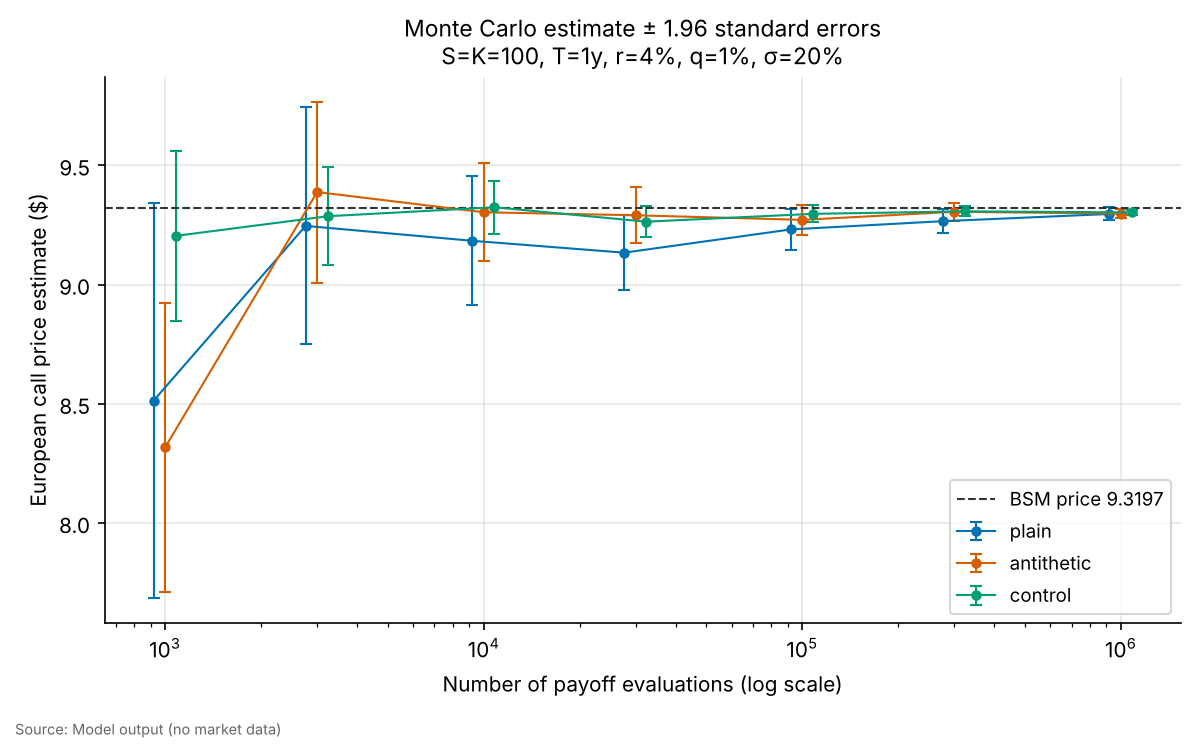

In [6]:
display(pd.read_csv(RES / "mc_variance_reduction.csv"))
display(Image(FIG / "03_mc_convergence.png"))

## 2. SPY implied-volatility surface
The chain snapshot is cached in `data/raw/`; run `python -m src.pipeline --refresh-chain` to take a new one.

In [7]:
surf = surface.run()
print(json.dumps(surf, indent=2, default=str))

{
  "snapshot_utc": "2026-10-23T14:03:52+00:00",
  "spot": 760.8800048828125,
  "dividend_yield_q": 0.00987697377245236,
  "r_range": [
    0.04008572353928564,
    0.046979001193994605
  ],
  "n_raw": 9280,
  "n_clean": 2688,
  "n_expiries_fitted": 23,
  "atm_vol_1m_pct": 15.538359241853716,
  "atm_vol_1y_pct": 17.59746376182296,
  "skew_90_110_1m_volpts": 13.742157298524424,
  "skew_90_110_1y_volpts": 5.865948815253863,
  "svi_median_rmse_in_sample_volpts": 0.12535612380104985,
  "svi_median_rmse_out_of_sample_volpts": 0.130706982937379,
  "iv_solver_counts": {
    "newton": 2688,
    "brent": 0,
    "failed": 0
  },
  "parity_median_diff_bp": -3.9735856031319905,
  "parity_median_implied_q": 0.01112762406863526,
  "american_minus_bsm_iv_median_abs_volpts": 0.04329457955167815,
  "american_minus_bsm_iv_max_abs_volpts": 1.2736071879142108,
  "american_minus_euro_tree_iv_max_abs_volpts": 1.2618316849426354,
  "svi_slices_wing_slope_above_2": 3,
  "calendar_arb_violations": 0,
  "calend

In [8]:
display(pd.read_csv(RES / "chain_cleaning.csv"))

,step,rows_remaining
0,raw chain,9280
1,"two-sided quote (bid > 0, ask > bid)",8377
2,traded within 3 business days,5578
3,relative spread <= 50%,5355
4,T >= 7 calendar days,4670
5,-0.4 <= ln(K/F) <= 0.25,4025
6,out-of-the-money only,2688
7,mid inside European no-arbitrage bounds,2688
8,implied vol solved,2688


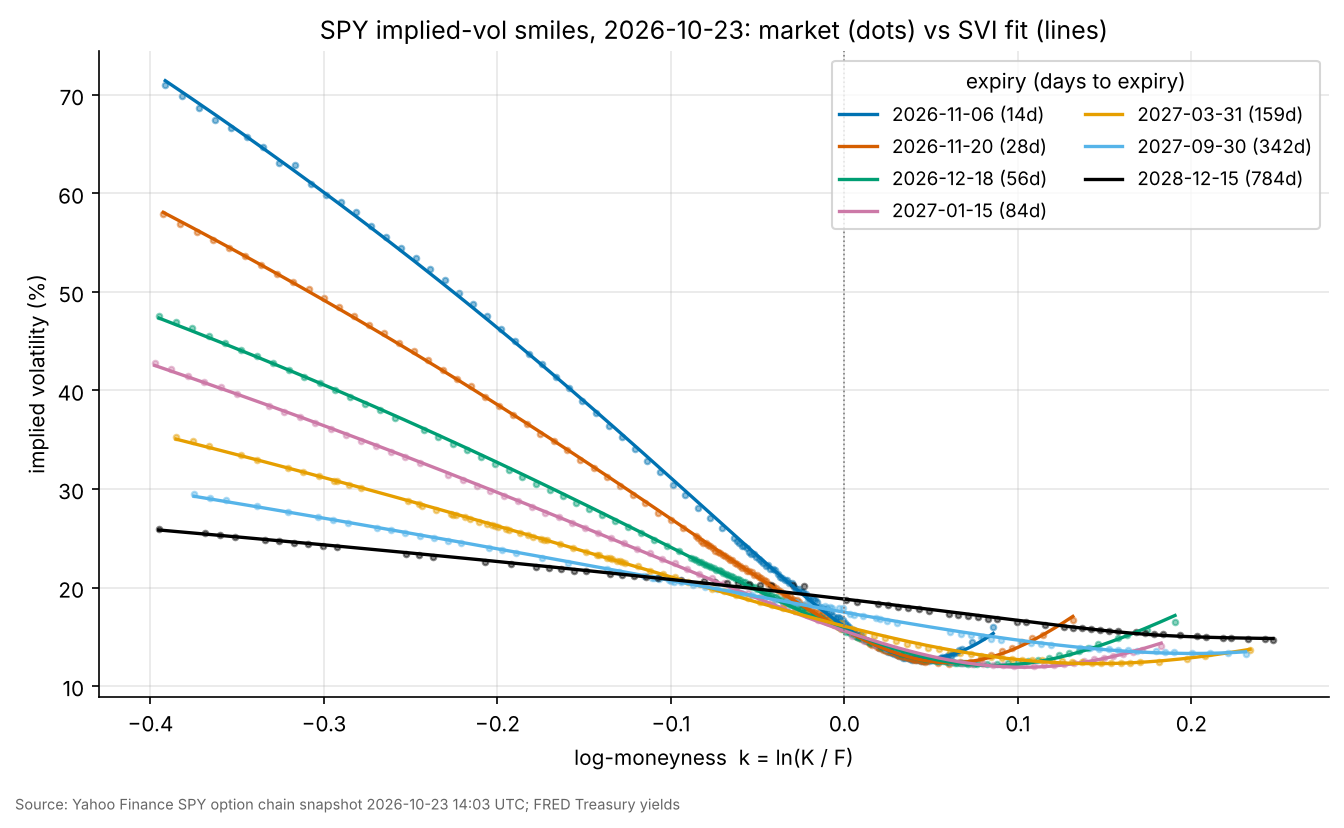

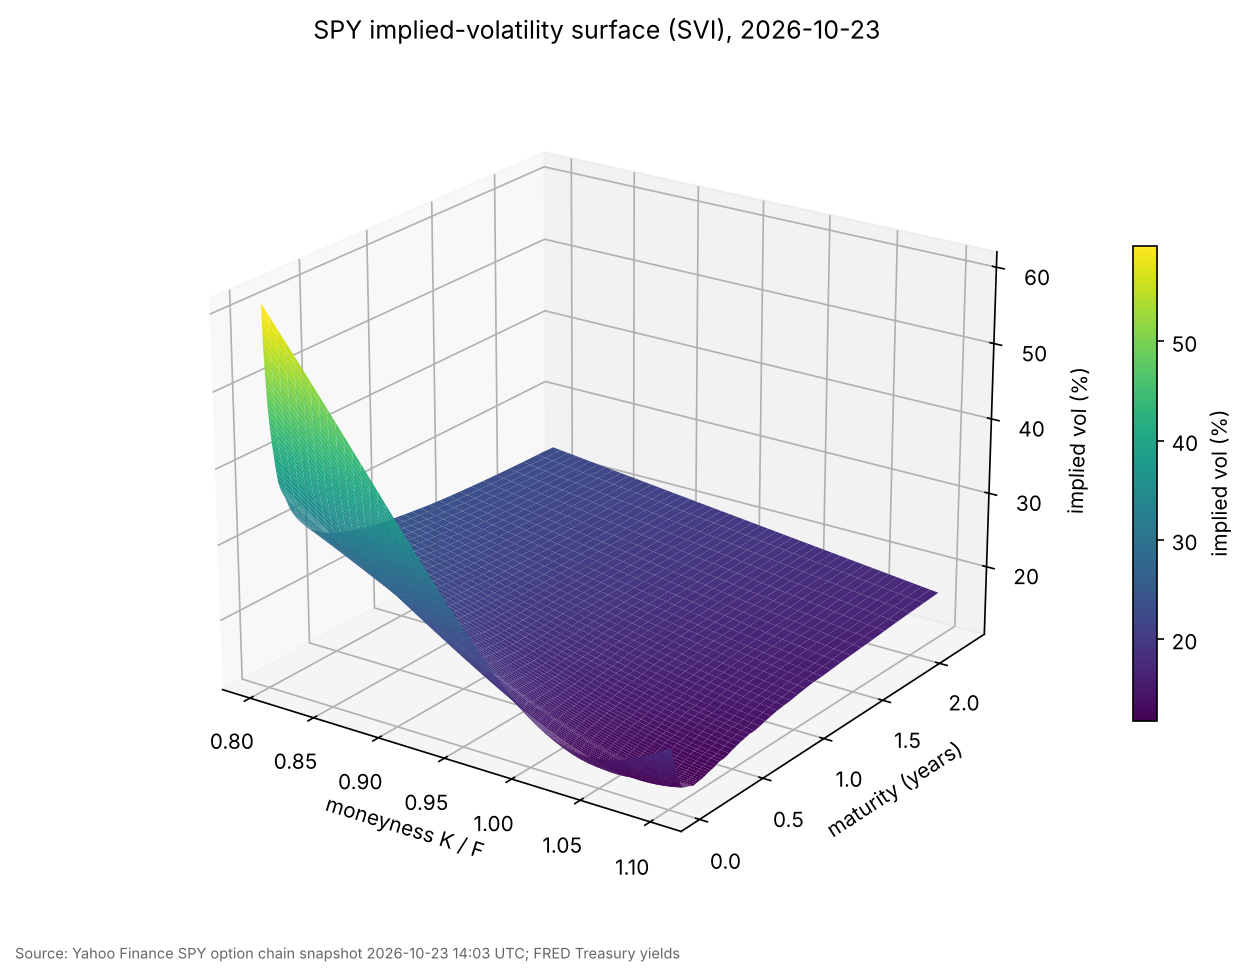

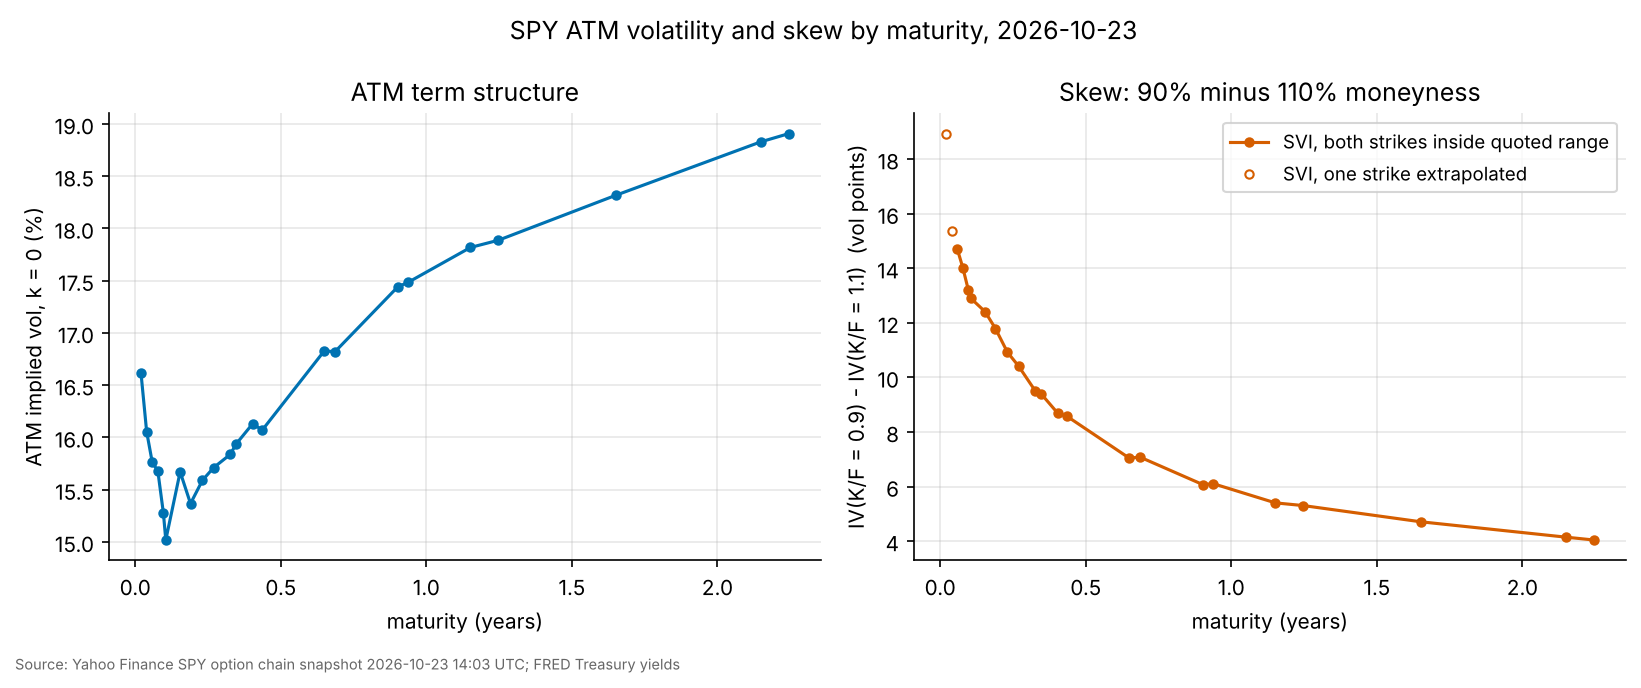

In [9]:
display(Image(FIG / "04_iv_smiles.png"))
display(Image(FIG / "05_iv_surface_3d.png"))
display(Image(FIG / "06_atm_term_structure_skew.png"))

SVI fit quality per expiry (every 5th strike held out) and the put–call parity diagnostic:

In [10]:
svi = pd.read_csv(RES / "svi_fit.csv")
display(svi[[c for c in svi.columns if c in ("expiry", "days", "n_points", "n_train", "n_test") or "rmse" in c]])
display(pd.read_csv(RES / "parity_check.csv"))
display(pd.read_csv(RES / "american_iv_diagnostic.csv").describe())

,expiry,days,n_points,n_train,n_test,rmse_in_sample_volpts,rmse_out_of_sample_volpts,rmse_full_fit_volpts
0,2026-10-30,7.2473,192,154,38,0.4766,0.5216,0.4846
1,2026-11-06,14.2890,144,116,28,0.2842,0.2756,0.2821
2,2026-11-13,21.2890,144,116,28,0.1852,0.1525,0.1789
3,2026-11-20,28.2890,150,120,30,0.1315,0.1885,0.1398
4,2026-11-27,35.2890,129,104,25,0.0984,0.1245,0.1038
5,2026-11-30,38.2890,221,177,44,0.0951,0.0815,0.0925
6,2026-12-18,56.2890,178,143,35,0.1710,0.1691,0.1704
7,2026-12-31,69.2890,270,216,54,0.2562,0.2767,0.2590
8,2027-01-15,84.2890,79,64,15,0.1690,0.1618,0.1675
9,2027-01-29,98.2890,129,104,25,0.1374,0.1307,0.1360


,expiry,T,n_strikes,F_model,F_parity_median,diff_bp,q_implied
0,2026-10-30,0.0199,67,761.3365,761.0340,-3.9736,0.0299
1,2026-11-06,0.0391,60,761.7804,761.5986,-2.3856,0.0160
2,2026-11-13,0.0583,59,762.2218,762.1924,-0.3857,0.0105
3,2026-11-20,0.0775,69,762.6635,762.7636,1.3116,0.0082
4,2026-11-27,0.0967,50,763.1146,763.2845,2.2266,0.0076
5,2026-11-30,0.1049,61,763.3109,763.3852,0.9735,0.0089
6,2026-12-18,0.1542,71,764.5100,764.2680,-3.1647,0.0119
7,2026-12-31,0.1898,58,765.3985,764.3535,-13.6523,0.0171
8,2027-01-15,0.2309,16,766.4472,765.6828,-9.9734,0.0142
9,2027-01-29,0.2693,38,767.4275,767.0096,-5.4448,0.0119


,T,strike,k,iv_bsm,iv_american_tree,iv_european_tree,amer_minus_bsm_volpts,amer_minus_euro_tree_volpts
count,237.0000,237.0000,237.0000,237.0000,237.0000,237.0000,237.0000,237.0000
mean,0.3933,735.0970,-0.0563,0.2193,0.2178,0.2193,-0.1449,-0.1532
std,0.4155,95.2043,0.1314,0.1023,0.1028,0.1025,0.2940,0.2852
min,0.0775,515.0000,-0.3927,0.1227,0.1230,0.1230,-1.2736,-1.2618
25%,0.0775,700.0000,-0.1083,0.1484,0.1483,0.1483,-0.1376,-0.1345
50%,0.0775,742.0000,-0.0329,0.1882,0.1861,0.1881,-0.0193,-0.0261
75%,0.9377,785.0000,0.0212,0.2401,0.2394,0.2400,0.0065,-0.0000
max,0.9377,990.0000,0.2312,0.5790,0.5807,0.5808,0.1717,0.0000


## 3. Delta-hedging a short 1-month ATM SPY call

In [11]:
hed = hedging.run()
print(json.dumps(hed, indent=2, default=str))

{
  "n_windows": 5465,
  "first_t0": "2005-01-03",
  "last_t0": "2026-09-23",
  "cost_bp": 1.0,
  "daily_implied": {
    "mean_pnl_bp_of_spot": 40.04387253078077,
    "hac_t": 12.701948094834421,
    "hac_p": 5.767588920493263e-37,
    "mean_pnl_pct_of_premium": 18.387526491254903,
    "pct_prem_hac_t": 13.79510805643782,
    "pct_prem_hac_p": 2.727438917747341e-43,
    "mean_premium_bp_of_spot": 219.77536300820924,
    "frac_positive": 0.8106129917657823,
    "worst_t0": "2008-10-08",
    "worst_pnl_bp_of_spot": -521.4367497067999,
    "worst_pnl_pct_of_premium": -80.18763242462735
  },
  "std_eps_bp": {
    "implied": {
      "daily": 54.49776787381038,
      "weekly": 80.0023737091329,
      "ratio_weekly_to_daily": 1.467993586349783
    },
    "forecast": {
      "daily": 58.1003112015093,
      "weekly": 82.16693098355094,
      "ratio_weekly_to_daily": 1.4142253162564205
    },
    "oracle": {
      "daily": 28.818841482035232,
      "weekly": 69.90870493866207,
      "ratio_week

In [12]:
summ = pd.read_csv(RES / "hedging_summary.csv")
cols = ["variant", "h", "n", "mean_pnl_bp", "std_pnl_bp", "mean_pnl_pct_prem", "mean_edge_bp", "mean_theta_bp",
        "mean_gamma_bp", "mean_costs_bp", "mean_residual_bp", "std_eps_bp", "hac_t", "hac_p", "nonoverlap_t", "skew", "kurt"]
summ[[c for c in cols if c in summ.columns]]

,variant,h,n,mean_pnl_bp,std_pnl_bp,mean_pnl_pct_prem,mean_edge_bp,mean_theta_bp,mean_gamma_bp,mean_costs_bp,mean_residual_bp,std_eps_bp,hac_t,hac_p,nonoverlap_t,skew,kurt
0,implied,1,5465,40.0439,66.2198,18.3875,0.0000,123.4893,-82.1349,2.4059,1.0954,54.4978,12.7019,0.0000,8.8683,-0.7540,9.5457
1,implied,2,5465,42.9457,70.8220,19.3735,0.0000,122.9625,-79.0057,2.0874,1.0764,63.9313,13.6041,0.0000,10.0952,-0.4590,7.5540
2,implied,5,5465,45.3886,89.5792,20.0811,0.0000,121.1311,-75.6376,1.8029,1.6980,80.0024,12.1198,0.0000,9.3133,-0.8440,9.0489
3,implied,10,5465,48.8838,111.4146,21.6973,0.0000,117.6230,-69.7856,1.6702,2.7166,99.2249,10.7727,0.0000,9.6335,-1.1580,10.1112
4,implied,21,5465,50.0764,147.0744,22.2728,0.0000,109.7870,-68.0437,1.0267,9.3597,131.6081,8.0811,0.0000,6.0607,-1.9682,16.2154
5,forecast,1,5465,38.4476,68.5051,17.6276,41.0750,92.4769,-93.9352,2.5990,1.4299,58.1003,12.0659,0.0000,7.6181,-0.7062,9.1847
6,forecast,2,5465,41.7407,72.8937,18.8447,41.0750,92.3997,-90.7506,2.2192,1.2358,66.7803,13.2155,0.0000,9.1450,-0.5855,8.4353
7,forecast,5,5465,44.2161,91.3687,19.5057,41.0750,92.1043,-88.6368,1.8774,1.5511,82.1669,11.8731,0.0000,8.7489,-0.9811,10.0824
8,forecast,10,5465,47.9481,113.3465,21.2749,41.0750,91.2778,-83.8422,1.7131,1.1507,101.4940,10.5873,0.0000,9.5065,-1.3237,10.9161
9,forecast,21,5465,49.7180,146.9826,22.1125,41.0750,89.1981,-87.0599,1.0225,7.5273,131.7930,8.0516,0.0000,6.0002,-1.9513,16.0803


,h,n_rebalances,std_eps_implied_bp,std_eps_forecast_bp,std_eps_oracle_bp,theory_bp
0,1,21,54.4978,58.1003,28.8188,28.3948
1,2,11,63.9313,66.7803,45.4486,39.2331
2,5,5,80.0024,82.1669,69.9087,58.1921
3,10,3,99.2249,101.4940,94.9701,75.1257
4,21,1,131.6081,131.7930,133.8167,130.1215


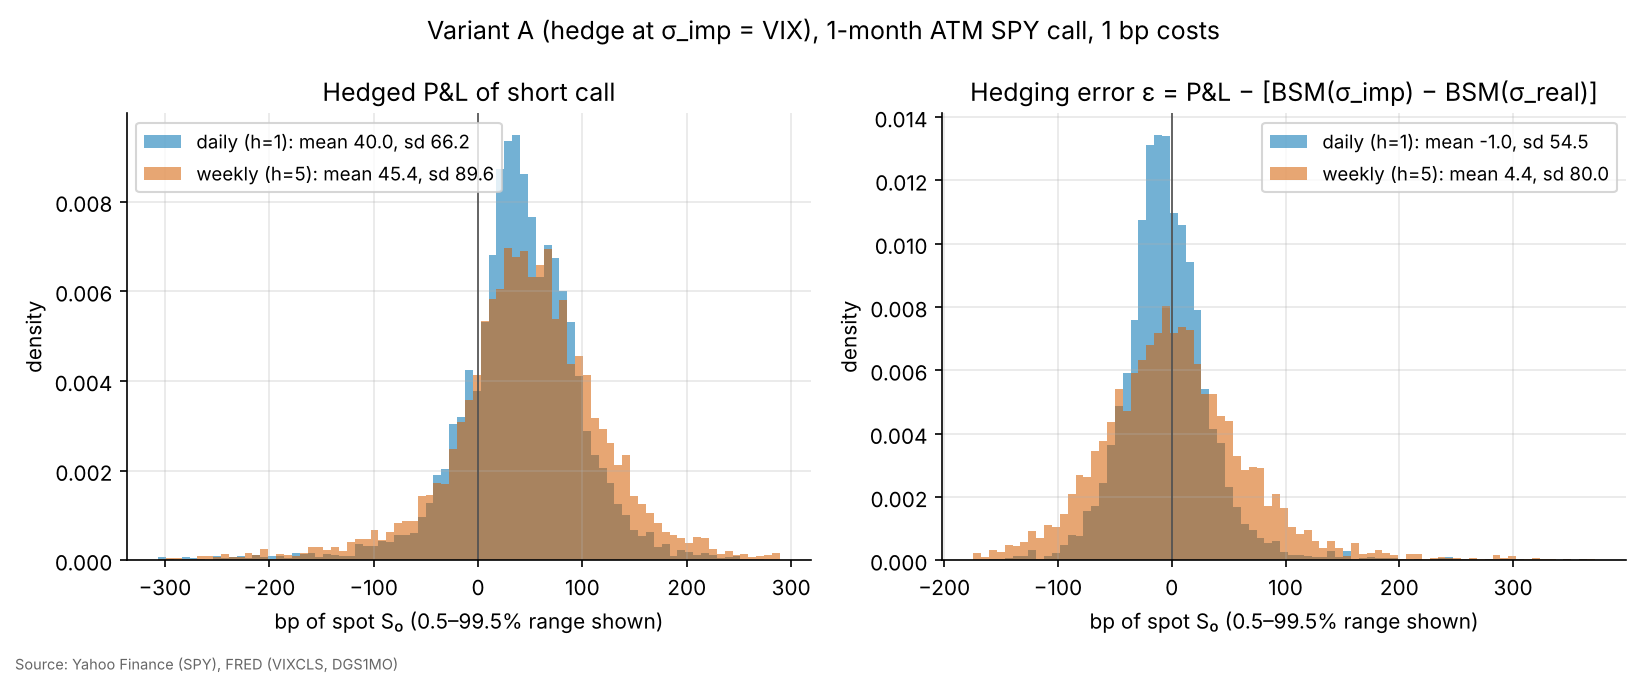

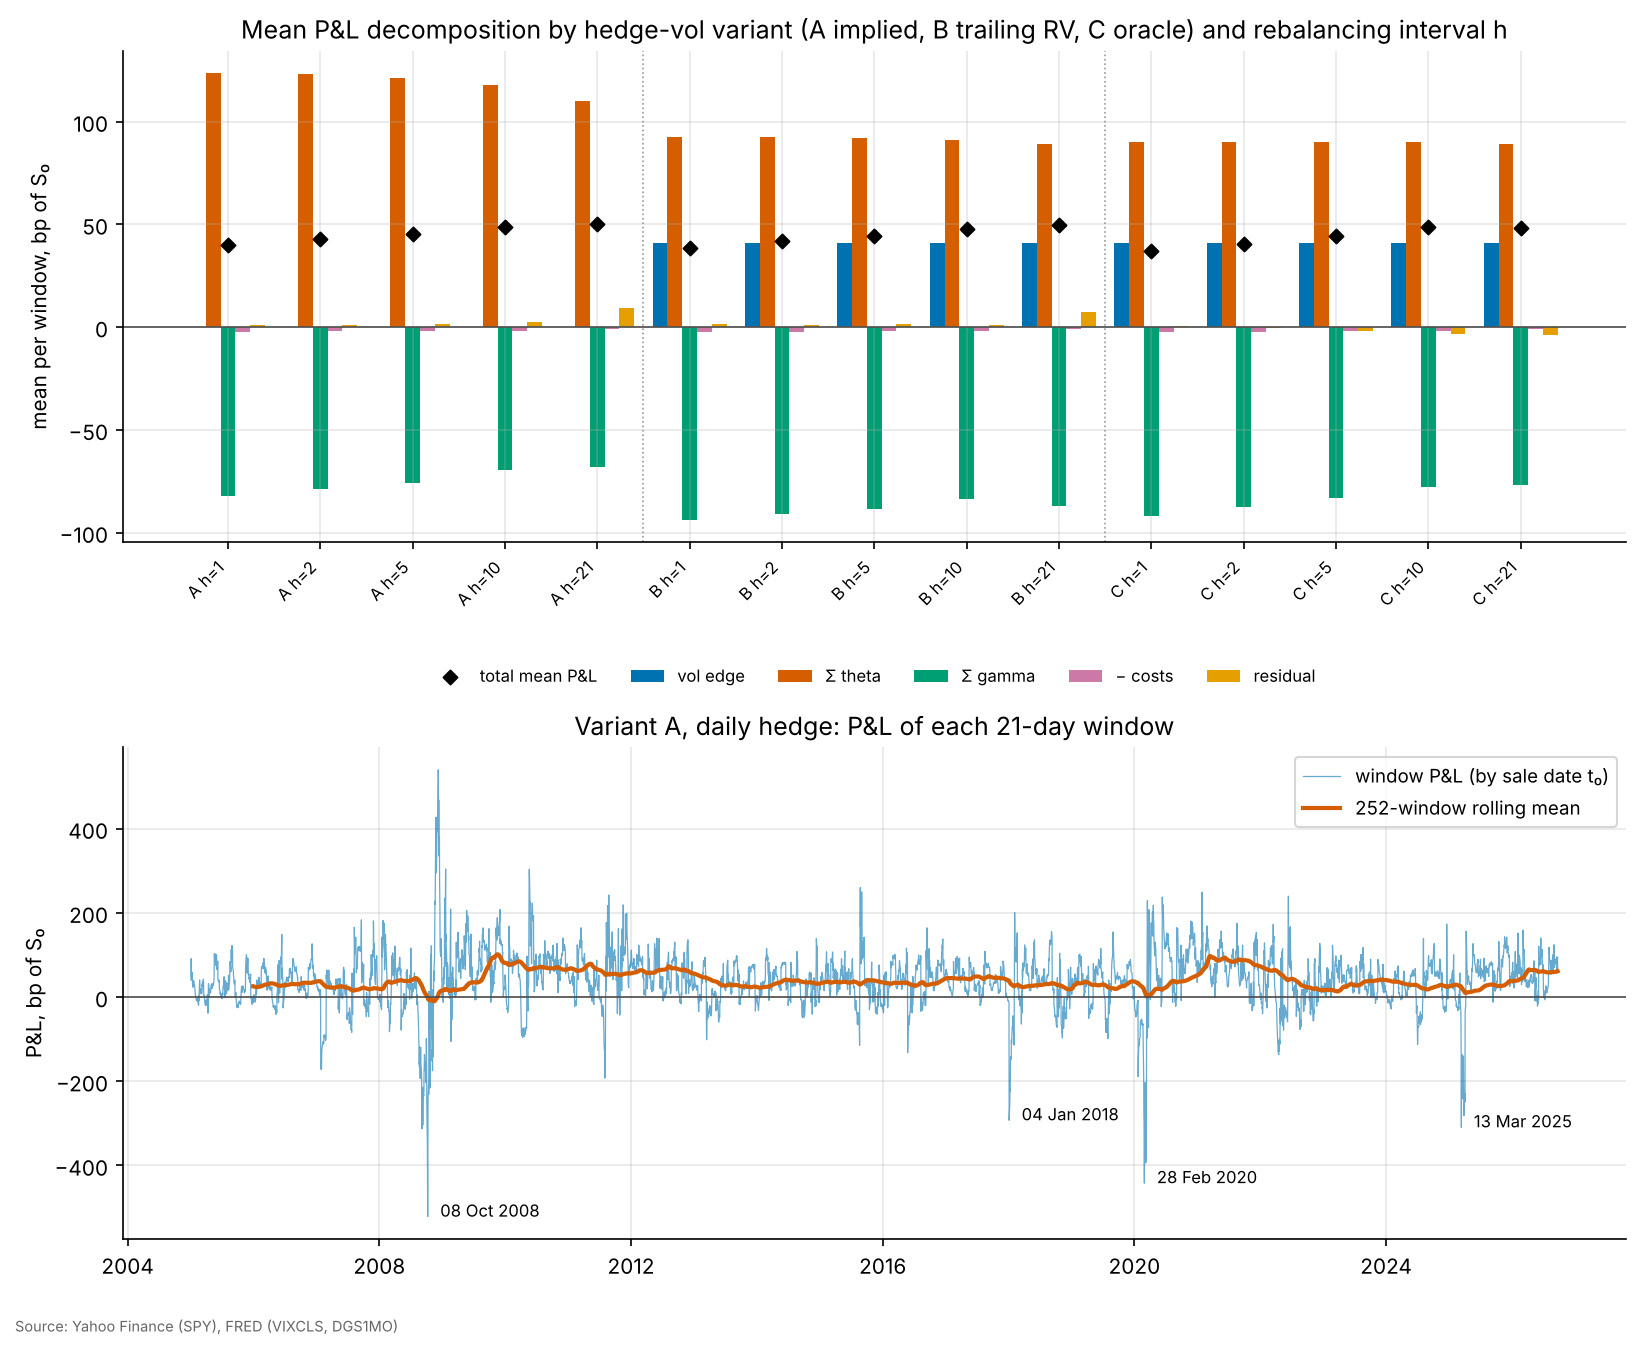

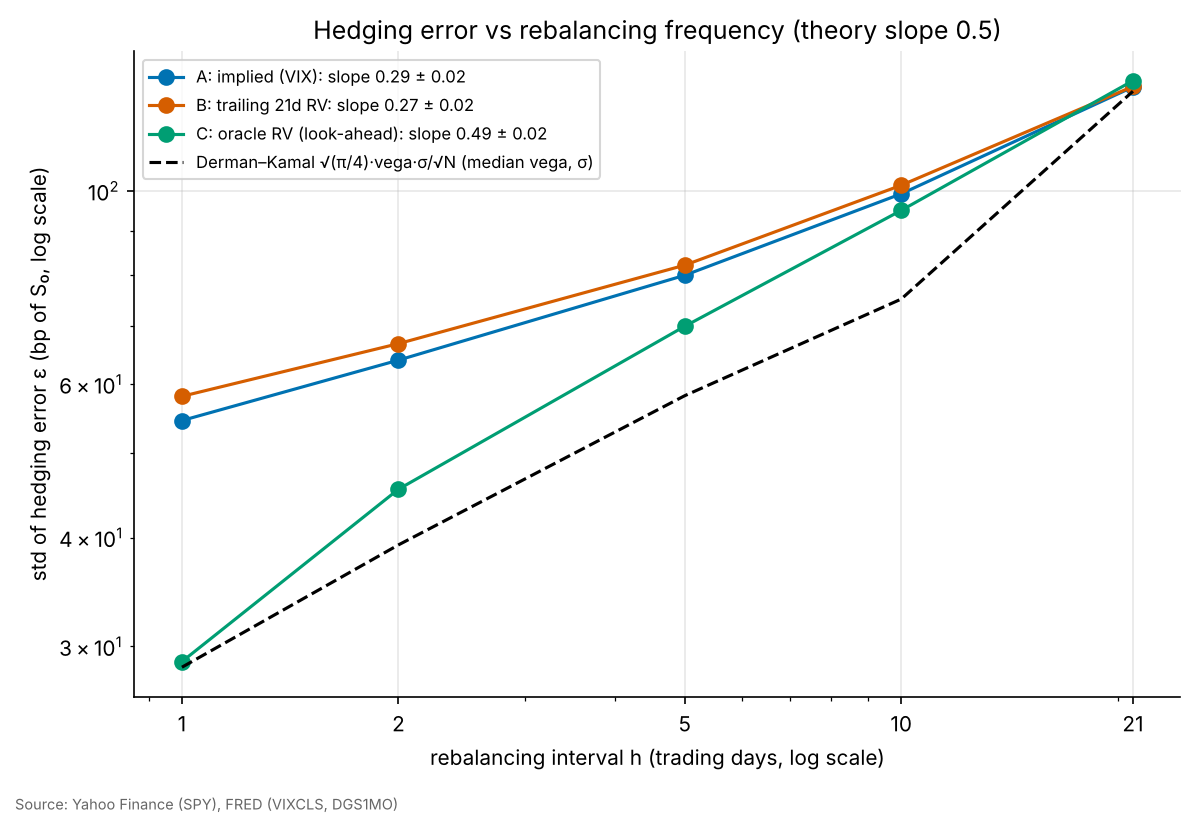

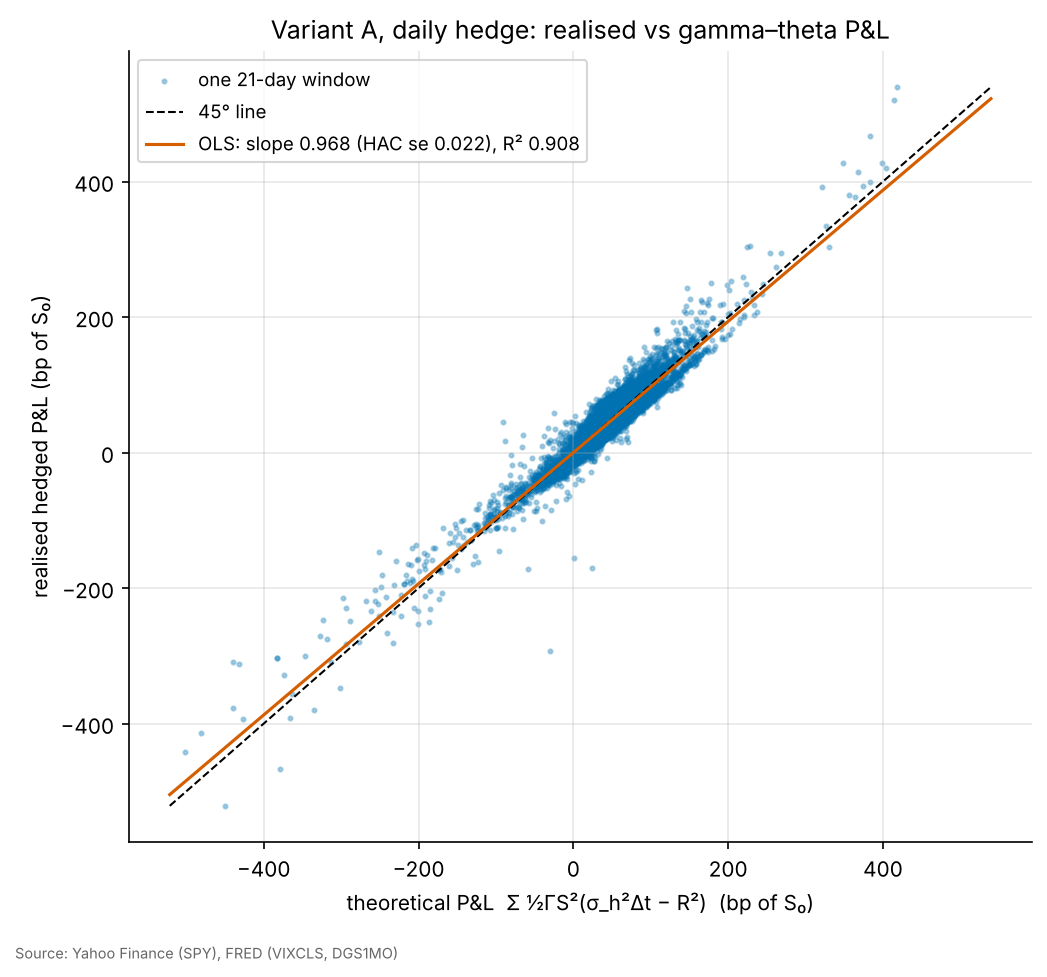

In [13]:
display(pd.read_csv(RES / "hedging_scaling.csv"))
for f in ["07_hedge_pnl_distribution", "08_pnl_decomposition", "09_hedging_error_scaling", "10_pnl_vs_theory"]:
    display(Image(FIG / f"{f}.png"))

In [14]:
tc = pd.read_csv(RES / "hedging_tc_sensitivity.csv")
tc.pivot_table(index=["variant", "h"], columns="cost_bp", values="mean_pnl_bp")

cost_bp      0.0000  1.0000  5.0000
variant  h                         
forecast 1  41.0484 38.4476 28.0445
         2  43.9613 41.7407 32.8580
         5  46.0946 44.2161 36.7019
         10 49.6622 47.9481 41.0917
         21 50.7413 49.7180 45.6251
implied  1  42.4514 40.0439 30.4139
         2  45.0344 42.9457 34.5906
         5  47.1926 45.3886 38.1729
         10 50.5549 48.8838 42.1993
         21 51.1038 50.0764 45.9666
oracle   1  39.5267 36.9372 26.5794
         2  42.8074 40.5953 31.7467
         5  46.0423 44.1697 36.6794
         10 50.1766 48.4641 41.6140
         21 49.3311 48.3084 44.2175

## Summary
* The pricing library reproduces Hull's textbook values; CRR converges to BSM at rate O(1/n);
  antithetic + control variates cut Monte Carlo variance by roughly 23×.
* The SPY surface shows a steep negative skew that flattens with maturity and an upward-sloping ATM term structure beyond ~2 months.
* Delta-hedged short calls earned a positive but crash-exposed P&L; realised P&L lines up with the
  ½ΓS²(σ²Δt − R²) gamma–theta formula (slope ≈ 1, R² ≈ 0.91), and hedging error scales as √Δt only when the hedge uses the true realised vol.
See README.md for the full discussion and limitations.